# Phase F scratch notebook: tiers
Work-in-progress outputs go to `data/scratch/F/`. Finished cells live in section 7 of the main notebook.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

# Same values as the main notebook's config cell. Change them there, not here.
SEED = 363
POSITIONS = ["QB", "RB", "WR", "TE"]
TRAIN_SEASONS = list(range(2020, 2025))
TEST_SEASON = 2025
TARGET = "fantasy_points_ppr"
CV_VALID_SEASONS = [2022, 2023, 2024]
TOP_N = 12

## Shared data
`features` has one row per player-week (2020-2025) with the target. `FEATURE_FAMILIES` lists the only columns that may be used as model inputs. `train` drops 2025, which is only for the final test (Phase H).

In [2]:
features = pd.read_parquet(PROCESSED_DIR / "features.parquet")
FEATURE_FAMILIES = json.loads((PROCESSED_DIR / "feature_families.json").read_text())
ALL_FEATURES = [c for cols in FEATURE_FAMILIES.values() for c in cols]

train = features[features["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
print(f"train: {train.shape}, features: {len(ALL_FEATURES)}")

train: (18402, 55), features: 48


## Shared evaluation (copied exactly from main notebook section 5.6; a test checks they match)

In [3]:
def cv_folds(data):
    for season in CV_VALID_SEASONS:
        train = data.index[data["season"].between(TRAIN_SEASONS[0], season - 1)]
        valid = data.index[data["season"] == season]
        yield season, train, valid


def top_n_hit_rate(week):
    predicted_top = set(week.nlargest(TOP_N, "pred").index)
    actual_top = set(week.nlargest(TOP_N, TARGET).index)
    return len(predicted_top & actual_top) / TOP_N


def evaluate(data, pred):
    d = data.assign(pred=np.asarray(pred))
    groups = d.groupby(["season", "week", "position"])
    return {
        "rmse": float(np.sqrt(((d["pred"] - d[TARGET]) ** 2).mean())),
        "mae": float((d["pred"] - d[TARGET]).abs().mean()),
        "spearman": float(groups.apply(lambda w: w["pred"].corr(w[TARGET], method="spearman")).mean()),
        "top12_hit_rate": float(groups.apply(top_n_hit_rate).mean()),
    }


def cross_validate(model, data, columns):
    """Fit on each expanding-window fold; return mean metrics and the out-of-fold predictions."""
    from sklearn.base import clone
    preds = pd.Series(np.nan, index=data.index)
    for season, train, valid in cv_folds(data):
        fitted = clone(model).fit(data.loc[train, columns], data.loc[train, TARGET])
        preds.loc[valid] = fitted.predict(data.loc[valid, columns])
    scored = preds.notna()
    return evaluate(data[scored], preds[scored]), preds

In [4]:
# Names the main notebook defines before section 7.
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
KEY = ["gsis_id", "season", "week"]
BOOTSTRAP_DRAWS = 5000
TIER_CUTS = [12, 24]
train_features = train
SCRATCH_DIR = ROOT / "data" / "scratch" / "F"
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)

## 7. Tiers (extension)
The instructor's question: tiers come from points, so does a classifier that predicts tiers directly do any better than tiers cut from our points regression?
- **Tiers (fixed, not tuned):** within each position-week, rank players by actual PPR points. Tier 1 = ranks 1-12 (a starter in a 12-team league), tier 2 = ranks 13-24, tier 3 = everyone else.
- **Three ways to predict a tier:** cut our regression's predicted ranks at the same places, train a classifier on the same 48 features to predict the tier directly, and cut the experts' ranks (ECR).
- **Scoring:** macro F1 (each tier counts equally, so the large tier 3 cannot dominate), computed inside each position-week and then averaged, the same way Spearman is in 5.6. Also precision and recall per tier, and confusion matrices.
- **Data:** the CV seasons 2022-2024 only. 2025 is not used here, and nothing in this section changes the regression.

### 7.1 Tier labels and tiers cut from the regression

In [5]:
TIERS = [1, 2, 3]


def cut_tiers(rows, score):
    "Tier 1, 2, or 3 from the rank of `score` within each position-week (highest score = rank 1)."
    rank = rows.groupby(["season", "week", "position"])[score].rank(ascending=False, method="first")
    return np.select([rank <= TIER_CUTS[0], rank <= TIER_CUTS[1]], [1, 2], default=3)


saved_regression = pd.read_parquet(PROCESSED_DIR / "preds_regression.parquet")
tier_rows = train_features.assign(tier_actual=cut_tiers(train_features, TARGET))
tier_rows["pred"] = tier_rows[KEY].merge(saved_regression, on=KEY, how="left", validate="one_to_one")["pred"].to_numpy()
tier_cv = tier_rows[tier_rows["season"].isin(CV_VALID_SEASONS)].copy()
assert tier_cv["pred"].notna().all(), "every CV player-week needs a regression prediction"
tier_cv["tier_from_regression"] = cut_tiers(tier_cv, "pred")

print(f"{len(tier_cv):,} player-weeks in {CV_VALID_SEASONS[0]}-{CV_VALID_SEASONS[-1]}. Share of each position in each tier:")
pd.crosstab(tier_cv["position"], tier_cv["tier_actual"], normalize="index").loc[POSITIONS].round(3).add_prefix("tier ")

11,207 player-weeks in 2022-2024. Share of each position in each tier:


tier_actual,tier 1,tier 2,tier 3
position,,,
QB,0.375,0.375,0.249
RB,0.320,0.320,0.360
WR,0.132,0.132,0.737
TE,0.256,0.256,0.488


**What we see:**
- The tiers are imbalanced, and how much depends on the position. A position-week has about 32 QBs but 91 WRs, so tier 1 holds 37% of QBs but only 13% of WRs, and tier 3 holds 74% of WRs.
- Overall, tier 3 is the largest class. A classifier that ignores imbalance will lean toward it, so we compare class weighting against none and score with macro F1.

### 7.2 A classifier that predicts the tier directly
Three course classifiers, each with a small grid, with and without `class_weight="balanced"` (each tier weighted by the inverse of its size).
Tuning uses the season folds from `cv_folds()` and picks the highest macro F1 (within position-week). The winner is then refit every week, like the regression,
so both methods learn from the same games.

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support

TIER_MODELS = {
    "Logistic regression": lambda **p: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, **p)),
    "Random forest": lambda **p: RandomForestClassifier(n_estimators=300, random_state=SEED, **p),
    "Gradient boosting": lambda **p: HistGradientBoostingClassifier(max_iter=300, max_leaf_nodes=8, random_state=SEED, **p),
}
TIER_GRIDS = {"Logistic regression": ("C", [0.01, 0.1, 1.0]),            # one setting tuned per model
              "Random forest": ("min_samples_leaf", [10, 30, 100]),
              "Gradient boosting": ("learning_rate", [0.02, 0.05, 0.1])}
CLASS_WEIGHTS = {"no weighting": None, "balanced": "balanced"}


def tier_splits(data, refit_weekly):
    "(training rows, rows to predict) pairs for the CV seasons. Training rows are always from earlier games."
    for season, train, valid in cv_folds(data):
        earlier, this_season = data.loc[train], data.loc[valid]
        if not refit_weekly:
            yield earlier, this_season
            continue
        for week in sorted(this_season["week"].unique()):
            yield pd.concat([earlier, this_season[this_season["week"] < week]]), this_season[this_season["week"] == week]


def fit_and_predict_tiers(model, fit_rows, predict_rows):
    fitted = clone(model).fit(fit_rows[ALL_FEATURES], fit_rows["tier_actual"])
    return pd.DataFrame(fitted.predict_proba(predict_rows[ALL_FEATURES]), index=predict_rows.index, columns=fitted.classes_)


def tier_probabilities(model, data, refit_weekly=False):
    "Out-of-fold probability of each tier for every CV player-week."
    blocks = Parallel(n_jobs=-1)(delayed(fit_and_predict_tiers)(model, fit_rows, predict_rows)
                                 for fit_rows, predict_rows in tier_splits(data, refit_weekly))
    return pd.concat(blocks).sort_index()


def macro_f1(actual, predicted):
    return f1_score(actual, predicted, labels=TIERS, average="macro", zero_division=0)


def position_week_macro_f1(rows, column):
    "Macro F1 inside each position-week, where the tiers are defined. One value per position-week."
    return rows.groupby(["season", "week", "position"]).apply(lambda w: macro_f1(w["tier_actual"], w[column]))


tuning_rows = []
for name, (param, values) in TIER_GRIDS.items():
    for value in values:
        for weighting, class_weight in CLASS_WEIGHTS.items():
            probs = tier_probabilities(TIER_MODELS[name](class_weight=class_weight, **{param: value}), tier_rows)
            scored = tier_rows.loc[probs.index].assign(tier_pred=probs.idxmax(axis=1))
            tuning_rows.append({"model": name, "setting": f"{param}={value}", "params": {param: value},
                                "weighting": weighting, "macro F1": position_week_macro_f1(scored, "tier_pred").mean()})
tier_tuning = pd.DataFrame(tuning_rows)

best = tier_tuning.loc[tier_tuning["macro F1"].idxmax()]
TIER_CHOICE = {"model": best["model"], "params": best["params"], "class_weight": CLASS_WEIGHTS[best["weighting"]],
               "refit": "every week", "tier_cuts": TIER_CUTS}
print("Chosen:", TIER_CHOICE)
tier_tuning.pivot_table(index=["model", "setting"], columns="weighting", values="macro F1", sort=False).round(4)

Chosen: {'model': 'Gradient boosting', 'params': {'learning_rate': 0.1}, 'class_weight': 'balanced', 'refit': 'every week', 'tier_cuts': [12, 24]}


weighting                                 no weighting  balanced
model               setting                                     
Logistic regression C=0.01                      0.4327    0.4478
                    C=0.1                       0.4367    0.4495
                    C=1.0                       0.4351    0.4504
Random forest       min_samples_leaf=10         0.4332    0.4418
                    min_samples_leaf=30         0.4276    0.4400
                    min_samples_leaf=100        0.4205    0.4360
Gradient boosting   learning_rate=0.02          0.4309    0.4541
                    learning_rate=0.05          0.4340    0.4510
                    learning_rate=0.1           0.4324    0.4591

**What we see:**
- Balanced class weights beat no weighting for every model and setting, by 0.009 to 0.027 macro F1. So the weighting stays.
- The three models are close. The best setting is 0.459 for gradient boosting, 0.450 for logistic regression, and 0.442 for random forest. Gradient boosting (learning rate 0.1, balanced) is chosen.

In [7]:
tier_model = TIER_MODELS[TIER_CHOICE["model"]](class_weight=TIER_CHOICE["class_weight"], **TIER_CHOICE["params"])
tier_probs = tier_probabilities(tier_model, tier_rows, refit_weekly=True)
assert tier_probs.index.equals(tier_cv.index)

# Raw labels: the most likely tier for each player, judged on its own.
tier_cv["tier_classifier"] = tier_probs.idxmax(axis=1)
# Quota version: rank players by expected tier (lower is better), then cut at 12 and 24 like the regression.
tier_cv["classifier_score"] = -(tier_probs * TIERS).sum(axis=1)
tier_cv["tier_classifier_quota"] = cut_tiers(tier_cv, "classifier_score")

print("Players per position-week the raw labels put in each tier (the actual tiers always hold 12, 12, and the rest):")
(tier_cv.groupby(["season", "week", "position"])["tier_classifier"].value_counts().unstack(fill_value=0)
 .groupby("position").mean().loc[POSITIONS].round(1).add_prefix("tier "))

Players per position-week the raw labels put in each tier (the actual tiers always hold 12, 12, and the rest):


tier_classifier,tier 1,tier 2,tier 3
position,,,
QB,10.4,19.1,2.4
RB,15.0,17.9,4.6
WR,12.4,2.2,76.7
TE,13.5,13.5,19.8


**What we see:**
- The raw labels do not keep the tier sizes. Each player is judged alone, so the classifier puts only 2.4 QBs per week in tier 3 (the real number is about 8) and only 2.2 WRs in tier 2 (the real number is 12).
- The reason: a middling WR is still more likely to land in tier 3 than tier 2, so tier 2 is rarely the most likely label for that player. A ranking does not have this problem, because it compares each player with the rest of that week.

### 7.3 Regression cut vs. classifier
All 11,207 CV player-weeks. The verdict uses each week's macro F1 (averaged over the four positions). We bootstrap the weekly gap between
the regression cut and the classifier's raw labels to get a 95% interval. Pooled macro F1 (all positions in one pile) is shown next to it
to make a point in the notes below. Precision, recall, and the confusion matrices are pooled.

,macro F1,pooled macro F1,accuracy,tier 1 precision,tier 2 precision,tier 3 precision,tier 1 recall,tier 2 recall,tier 3 recall
cut from regression,0.495,0.526,0.596,0.489,0.335,0.755,0.489,0.335,0.755
classifier (raw labels),0.454,0.536,0.594,0.466,0.366,0.773,0.498,0.402,0.717
classifier (quota cut),0.491,0.524,0.592,0.484,0.342,0.746,0.484,0.342,0.746


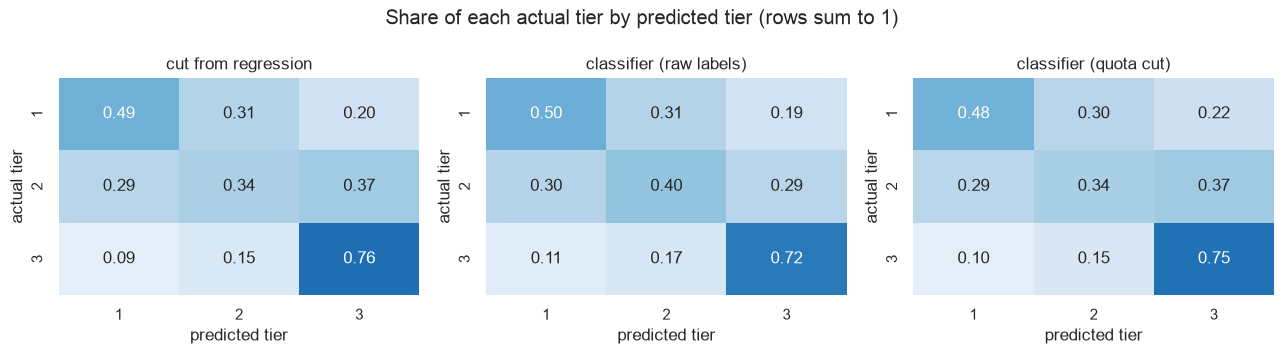

Weekly macro F1, regression cut minus classifier: +0.040 (95% interval +0.031 to +0.049); regression ahead in 47 of 54 weeks


In [8]:
TIER_METHODS = {"cut from regression": "tier_from_regression",
                "classifier (raw labels)": "tier_classifier",
                "classifier (quota cut)": "tier_classifier_quota"}


def tier_scores(rows, column):
    actual, predicted = rows["tier_actual"], rows[column]
    precision, recall, _, _ = precision_recall_fscore_support(actual, predicted, labels=TIERS, zero_division=0)
    return {"macro F1": position_week_macro_f1(rows, column).mean(), "pooled macro F1": macro_f1(actual, predicted),
            "accuracy": accuracy_score(actual, predicted),
            **{f"tier {t} precision": p for t, p in zip(TIERS, precision)},
            **{f"tier {t} recall": r for t, r in zip(TIERS, recall)}}


def weekly_macro_f1(rows, column):
    "Each week's macro F1, averaged over the four positions."
    return position_week_macro_f1(rows, column).groupby(["season", "week"]).mean()


def bootstrap_interval(values):
    rng = np.random.default_rng(SEED)
    means = [rng.choice(values, len(values)).mean() for _ in range(BOOTSTRAP_DRAWS)]
    return np.percentile(means, [2.5, 97.5])


tier_comparison = pd.DataFrame({name: tier_scores(tier_cv, column) for name, column in TIER_METHODS.items()}).T
display(tier_comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, column) in zip(axes, TIER_METHODS.items()):
    matrix = confusion_matrix(tier_cv["tier_actual"], tier_cv[column], labels=TIERS, normalize="true")
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=TIERS, yticklabels=TIERS)
    ax.set(title=name, xlabel="predicted tier", ylabel="actual tier")
plt.suptitle("Share of each actual tier by predicted tier (rows sum to 1)")
plt.tight_layout()
plt.show()

weekly_gap = weekly_macro_f1(tier_cv, "tier_from_regression") - weekly_macro_f1(tier_cv, "tier_classifier")
low, high = bootstrap_interval(weekly_gap.to_numpy())
print(f"Weekly macro F1, regression cut minus classifier: {weekly_gap.mean():+.3f} "
      f"(95% interval {low:+.3f} to {high:+.3f}); regression ahead in {(weekly_gap > 0).sum()} of {len(weekly_gap)} weeks")

**What we see:**
- **The regression cut wins.** Macro F1 within position-week is 0.495 for the regression cut and 0.454 for the classifier. The weekly gap is +0.040 (95% interval +0.031 to +0.049), and the regression is ahead in 47 of 54 weeks.
- **Pooled macro F1 points the wrong way** (0.536 for the classifier vs. 0.526). Pooling rewards knowing that QBs usually land in tiers 1-2 and WRs in tier 3. That is true but useless, because tiers are only compared within a position.
- **Turning the classifier into a ranking closes the gap.** The quota cut scores 0.491, almost the same as the regression (0.495). The classifier's information is about the same; it loses because of how it sizes the tiers.
- **Tier 2 is the hardest for every method** (recall 0.34 to 0.40), since it borders both other tiers. Tier 1 recall for the regression cut (0.489) is the same number as its top-12 hit rate in section 6.

### 7.4 Against the experts
Same rules as the final test: keep player-weeks with an expert rank made before kickoff, then re-cut every rank-based tier
(actual, regression, classifier quota, ECR) within those rows so all methods are judged on the same players. Macro F1 by position:

In [9]:
def macro_f1_by_position(rows, column):
    scores = position_week_macro_f1(rows, column)
    return {"all": scores.mean(), **scores.groupby("position").mean()}


expert_ranks = pd.read_parquet(PROCESSED_DIR / "ecr_weekly.parquet")
usable_ecr = expert_ranks.loc[~expert_ranks["played_before_snapshot"], KEY + ["ecr_pos_rank"]]
tier_matched = tier_cv.merge(usable_ecr, on=KEY, validate="one_to_one").assign(
    ecr_score=lambda d: -d["ecr_pos_rank"])
tier_matched["tier_actual"] = cut_tiers(tier_matched, TARGET)
tier_matched["tier_ecr"] = cut_tiers(tier_matched, "ecr_score")
for column, score in [("tier_from_regression", "pred"), ("tier_classifier_quota", "classifier_score")]:
    tier_matched[column] = cut_tiers(tier_matched, score)

MATCHED_METHODS = {**TIER_METHODS, "cut from ECR": "tier_ecr"}
expert_comparison = pd.DataFrame({name: macro_f1_by_position(tier_matched, column)
                                  for name, column in MATCHED_METHODS.items()}).T[["all"] + POSITIONS]
print(f"{len(tier_matched):,} player-weeks with a usable expert rank")
expert_comparison.round(3)

8,565 player-weeks with a usable expert rank


,all,QB,RB,WR,TE
cut from regression,0.499,0.494,0.492,0.475,0.536
classifier (raw labels),0.459,0.438,0.458,0.410,0.528
classifier (quota cut),0.493,0.487,0.489,0.460,0.537
cut from ECR,0.508,0.517,0.501,0.484,0.531


**What we see:**
- The experts are a little ahead: 0.508 for ECR vs. 0.499 for the regression cut, on 8,565 player-weeks.
- By position, the experts lead at QB (0.517 vs. 0.494), RB (0.501 vs. 0.492), and WR (0.484 vs. 0.475), and we lead at TE (0.536 vs. 0.531). This is the same pattern as the Spearman results in section 9.
- The classifier's raw labels are last at every position (0.410 to 0.528).

### 7.5 Saved tiers and the answer
`tier_results.parquet` has one row per CV player-week. `tier_actual`, `tier_from_regression`, and `tier_classifier` use the full player pool.
`tier_ecr` is filled only where a usable expert rank exists, and is cut within those rows (as in 7.4). `tier_choice.json` stores the
classifier settings and the 7.3 macro F1 scores.

In [10]:
tier_results = tier_cv[KEY + ["position", "tier_actual", "tier_from_regression", "tier_classifier"]].merge(
    tier_matched[KEY + ["tier_ecr"]], on=KEY, how="left", validate="one_to_one")
tier_results["tier_ecr"] = tier_results["tier_ecr"].astype("Int64")
tier_results.to_parquet(SCRATCH_DIR / "tier_results.parquet", index=False)
(SCRATCH_DIR / "tier_choice.json").write_text(json.dumps(
    {**TIER_CHOICE, "macro_f1": tier_comparison["macro F1"].round(6).to_dict()}, indent=2))
print(f"Saved {len(tier_results):,} rows; {tier_results['tier_ecr'].notna().sum():,} have an ECR tier")

Saved 11,207 rows; 8,565 have an ECR tier


**Answer to the instructor's question:** a separate tier classifier does not beat tiers cut from our points regression. On 2022-2024, the regression cut scores macro F1 0.495 and the best tuned classifier (gradient boosting with balanced class weights) scores 0.454. The regression cut is ahead in 47 of 54 weeks (gap +0.040, 95% interval +0.031 to +0.049). When we turn the classifier's probabilities into a ranking and cut it at the same places, it scores 0.491, about the same as the regression. So the instructor is right: tiers are a coarse version of the points ranking and carry the same information. The classifier only differs in how it fills the tiers, and it does that worse because it judges each player alone instead of against the rest of that week. That is why the points regression is our main task, and tiers are an extension read off it. Against the experts, tiers cut from ECR score 0.508 vs. our 0.499, the same small expert edge as in section 9.